In [3]:
%pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
df = pd.read_excel("Coffee Shop Sales.xlsx")
print("First five rows:")
print(df.head())
print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

First five rows:
   transaction_id transaction_date transaction_time  transaction_qty  \
0               1       2023-01-01         07:06:11                2   
1               2       2023-01-01         07:08:56                2   
2               3       2023-01-01         07:14:04                2   
3               4       2023-01-01         07:20:24                1   
4               5       2023-01-01         07:22:41                2   

   store_id   store_location  product_id  unit_price    product_category  \
0         5  Lower Manhattan          32         3.0              Coffee   
1         5  Lower Manhattan          57         3.1                 Tea   
2         5  Lower Manhattan          59         4.5  Drinking Chocolate   
3         5  Lower Manhattan          22         2.0              Coffee   
4         5  Lower Manhattan          57         3.1                 Tea   

            product_type               product_detail  
0  Gourmet brewed coffee             

In [5]:
df["transaction_date"] = pd.to_datetime(df["transaction_date"])
df["Month"] = df["transaction_date"].dt.month
df["Day"] = df["transaction_date"].dt.day
df["DayOfWeek"] = df["transaction_date"].dt.dayofweek
df["Hour"] = pd.to_datetime(
    df["transaction_time"].astype(str),
    format="%H:%M:%S"
).dt.hour
y = df["product_category"]
X = df[
    [
        "transaction_qty",
        "unit_price",
        "store_location",
        "Month",
        "Day",
        "DayOfWeek",
        "Hour"
    ]
]
X = pd.get_dummies(
    X,
    columns=["store_location"],
    dtype=int
)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)
print("\nInput features:")
print(X.head())
print("\nTarget classes:", label_encoder.classes_)


Input features:
   transaction_qty  unit_price  Month  Day  DayOfWeek  Hour  \
0                2         3.0      1    1          6     7   
1                2         3.1      1    1          6     7   
2                2         4.5      1    1          6     7   
3                1         2.0      1    1          6     7   
4                2         3.1      1    1          6     7   

   store_location_Astoria  store_location_Hell's Kitchen  \
0                       0                              0   
1                       0                              0   
2                       0                              0   
3                       0                              0   
4                       0                              0   

   store_location_Lower Manhattan  
0                               1  
1                               1  
2                               1  
3                               1  
4                               1  

Target classes: ['Bakery' 

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 119292
Testing samples: 29824


In [7]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)
model.fit(X_train, y_train)
print("\nDecision Tree model trained successfully!")


Decision Tree model trained successfully!


In [8]:
y_pred = model.predict(X_test)
print("\nActual categories:")
print(label_encoder.inverse_transform(y_test))
print("\nPredicted categories:")
print(label_encoder.inverse_transform(y_pred))


Actual categories:
['Coffee' 'Coffee' 'Branded' ... 'Coffee' 'Bakery' 'Tea']

Predicted categories:
['Tea' 'Tea' 'Coffee beans' ... 'Tea' 'Bakery' 'Tea']


In [9]:
accuracy = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=list(range(len(label_encoder.classes_))),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


Model Accuracy: 67.75 %

Classification Report:
                    precision    recall  f1-score   support

            Bakery       0.57      0.91      0.70      4559
           Branded       0.00      0.00      0.00       149
            Coffee       0.84      0.42      0.56     11684
      Coffee beans       0.42      1.00      0.59       351
Drinking Chocolate       0.99      0.38      0.55      2294
          Flavours       1.00      1.00      1.00      1358
         Loose Tea       0.00      0.00      0.00       242
Packaged Chocolate       0.00      0.00      0.00        97
               Tea       0.62      0.94      0.75      9090

          accuracy                           0.68     29824
         macro avg       0.49      0.52      0.46     29824
      weighted avg       0.74      0.68      0.65     29824




Confusion Matrix:
[[4126    0   52    0    6    0    0    0  375]
 [   0    0    0  149    0    0    0    0    0]
 [1979    0 4950    0    0    0    0    0 4755]
 [   0    0    0  351    0    0    0    0    0]
 [ 835    0  583    0  876    0    0    0    0]
 [   0    0    0    0    0 1358    0    0    0]
 [   0    0    0  242    0    0    0    0    0]
 [   0    0    0   97    0    0    0    0    0]
 [ 268    0  276    0    0    0    0    0 8546]]


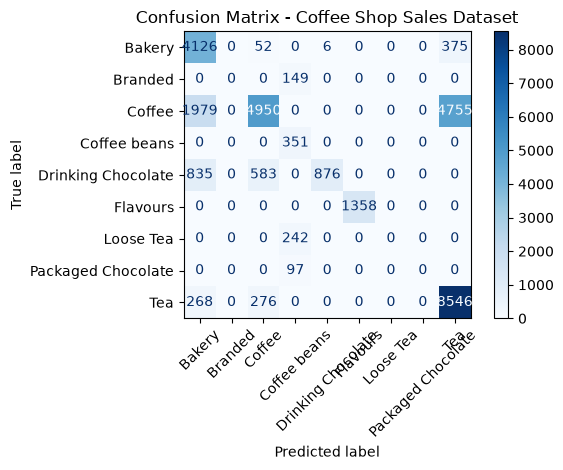

In [10]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=list(range(len(label_encoder.classes_)))
)
print("\nConfusion Matrix:")
print(cm)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
).plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix - Coffee Shop Sales Dataset")
plt.tight_layout()
plt.show()

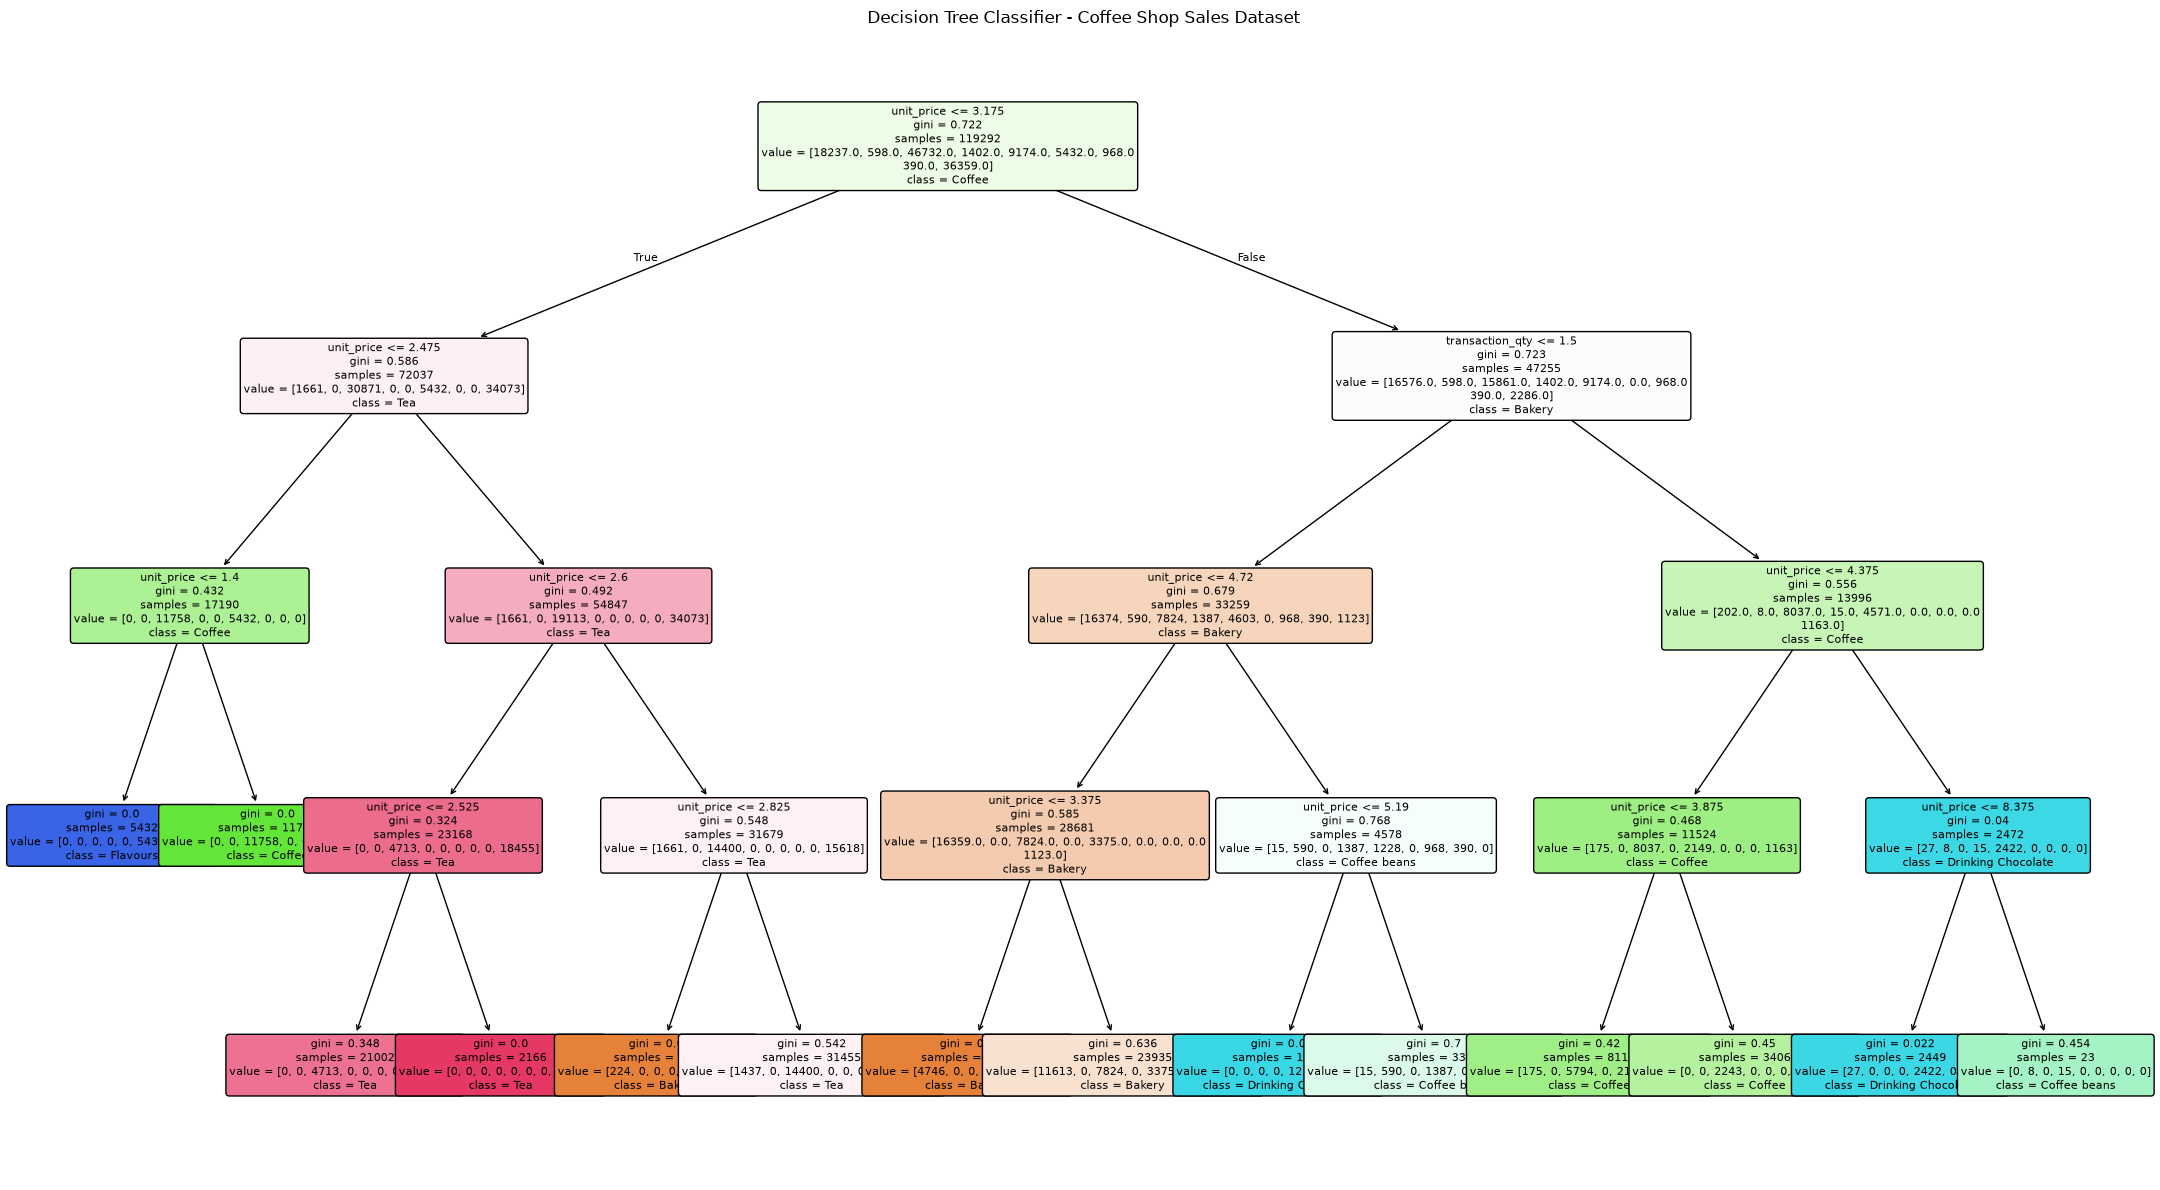

In [11]:
plt.figure(figsize=(22, 12))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=label_encoder.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Decision Tree Classifier - Coffee Shop Sales Dataset")
plt.tight_layout()
plt.show()